# 18 · Degree, network size and coupling-strength sweeps
## Goal
Complete this stage with three controlled finite-network comparisons: degree, size, and coupling strength. Retain the FHN graded E/I synapse rule and distinguish fixed recipient budgets from fixed individual contact strength.

This notebook is self-contained: Python, NumPy, SciPy, pandas, Matplotlib, NetworkX and IPython are required; earlier notebooks are not runtime dependencies. Run top-to-bottom from the notebook's directory. Results are written to `results/fhn_ei_degree_size_strength/`. There are 78 design labels, with exact duplicate conditions reused, plus selected solver and longer-window audits. No results from earlier notebooks are overwritten.

## Observations from the executed experiment
**15 graphs, 78 design labels, 56 unique main trajectories, 144 checks passed and eight figures inspected.** Exact duplicates are reused and mapped explicitly. Every realized graph is connected. The degree/size/strength slices are finite, paired experiments rather than a full factorial or graph-ensemble study.

For the **N=36 ring, source assignment 301, phase seed 11, window 400–1000**, R at degrees **4 / 8 / 12** is **0.219 / 0.491 / 0.634** under a fixed recipient budget B=0.08. With fixed contact coefficient g=0.02, it is **0.219 / 0.400 / 0.365**; the corresponding total budgets are **0.08 / 0.16 / 0.24**. This shows a material convention effect on the same realized graphs; it does not establish a universal relation between degree and order.

For the **degree-4 ring, B=0.08 and phase seed 11**, the size sweep gives **R=0.475 / 0.219 / 0.277** at **N=18 / 36 / 72**. Source fractions remain half E/I, but labels are not nested and populations/graphs change. The pattern is not a monotonic scaling law. Global phase coverage across all design labels is **93.0%–95.6%**; the per-condition coverage is saved rather than silently extrapolating endpoint phases.

For the **N=36, degree-4 ring and phase seed 11**, coupling budgets **0 / 0.04 / 0.08 / 0.16** give **R=0.069 / 0.331 / 0.219 / 0.087**. Stronger coupling does not monotonically increase measured phase order in this example. The B=0 result matches the initial phase-phasor benchmark: absolute errors for both phase fields are below **8.6×10⁻¹³**. At zero input, C is correctly undefined (NaN), not zero.

Selected longer-window results remain sensitive to observation time. For the same ring/phase at B=0.04,0.08,0.16, R changes **0.331→0.300**, **0.219→0.149**, and **0.087→0.082**, respectively, from 400–1000 to 1400–2000. These comparisons retain the original early-window event support and do not prove convergence or stable attractors.

Across the two selected numerical audits (72-node degree-4 regular graph at B=0.08; 36-node degree-12 ring at B=0.24), the largest sampled independent Radau state discrepancy on **0–200** is **4.55×10⁻⁹**. The largest tighter-DOP853 state discrepancy on **0–1000** is **2.91×10⁻⁷**. These selected checks do not certify every trajectory or asymptotic behavior. Frozen graph/coupling matrices, initial states, cache mappings, events, metrics and software versions accompany the notebook.


## Setup: separate the experimental questions
The continuous dimensionless equations remain
$$\dot v_i=v_i-v_i^3/3-w_i+0.5+\sum_jG_{ij}s_j(E_j-v_i),\quad\dot w_i=0.08(v_i+0.7-0.8w_i),$$
$$\dot s_j=\sigma(v_j/0.1)(1-s_j)-0.2s_j,\qquad E_j=+3\ (E),\;-3\ (I).$$
Rows of nonnegative G are recipients; columns are sources. Sources share reversal and gate across outgoing contacts; no self-input. Upward v=0 events are measurements without reset. There are no delays, noise, plasticity or physiological units.

All graphs are regular. For adjacency A and degree k, **fixed budget** uses $G=(B/k)A$, so each recipient and source coefficient sum is B; **fixed contact** uses $G=gA$ with g=0.02, so each coefficient sum is gk. These conventions coincide at k=4, B=0.08. They fix coefficients, not gate-weighted conductance or actual currents.

| Comparison | Fixed | Varied | Coupling convention |
|---|---|---|---|
| Degree | N=36; source labels and initial fields | k=4,8,12 | B=0.08 versus g=0.02 |
| Size | k=4; E/I fraction 1/2; B=0.08 | N=18,36,72 | fixed budget |
| Strength | N=36; k=4; graph/source labels/initial fields | B=0,0.04,0.08,0.16 | fixed budget |

Each graph specification has a circulant ring and random regular draws seeded 601/602. Random graphs are retained without connectivity selection; components and missing connected-path metrics are recorded. Two draws are illustrative realizations, not a graph-ensemble estimate. Same seed labels across degrees/sizes do not produce nested or edge-matched random graphs. Ring edges are nested as k increases at fixed N; changing size changes the ring itself. Ring positions are labels, not a physical distance law.

For each N, source assignment seed 301 gives exactly N/2 inhibitory labels; the same labels are used across graphs/degrees/strengths at that N. Assignments at different sizes are **not nested**. Phase seeds 11/29 generate initial isolated-cycle fields; phase fractions of the first labels are shared across sizes, but populations and E/I labels change. Thus the size sweep controls marginal initialization, fraction and degree, not identical populations. It is a finite-size sensitivity study, not a thermodynamic-limit extrapolation. Density k/(N−1) changes with N.

In [2]:
from pathlib import Path
import json,platform
import numpy as np
import pandas as pd
import scipy,matplotlib
from scipy.integrate import solve_ivp
from scipy.special import expit
from scipy.sparse import csr_matrix,lil_matrix
from scipy.sparse.csgraph import connected_components
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
OUT=Path('results/fhn_ei_degree_size_strength');OUT.mkdir(parents=True,exist_ok=True)
END=1000.;BURN=400.;DT=.5
A_REC,B_REC,EPS=.7,.8,.08;ALPHA,BETA,WIDTH=1.,.2,.1
PHASE_SEEDS=[11,29];G0=.02;ROW_BUDGET=.08
BLUE,ORANGE,GRAY,OLIVE,PINK='#2166AC','#C56A18','#555555','#8A7515','#A3537B'
plt.rcParams.update({'font.size':11,'figure.dpi':110,'savefig.dpi':160,'axes.spines.top':False,
 'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})
versions=dict(python=platform.python_version(),numpy=np.__version__,scipy=scipy.__version__,pandas=pd.__version__,matplotlib=matplotlib.__version__)
print(versions)
def save(fig,name):
 fig.savefig(OUT/(name+'.png'),bbox_inches='tight');plt.show();plt.close(fig)
import networkx as nx
import hashlib
versions['networkx']=nx.__version__
SIZES=[18,36,72];DEGREES=[4,8,12];BUDGETS=[0.,.04,.08,.16]
FAMILIES=['ring','regular601','regular602'];FAMILY_LABEL={'ring':'Ring','regular601':'Regular 601','regular602':'Regular 602'}
FAMILY_COLOR={'ring':BLUE,'regular601':ORANGE,'regular602':GRAY}
SOURCE={}
for n in SIZES:
 m=np.ones(n,dtype=bool);m[np.random.default_rng(301).choice(n,n//2,replace=False)]=False;SOURCE[n]=m

def ring_graph(n,k):
 if k%2 or k>=n:raise ValueError('Use even k<n')
 g=nx.Graph();g.add_nodes_from(range(n))
 for i in range(n):
  for shift in range(1,k//2+1):g.add_edge(i,(i+shift)%n)
 return g

def graph_name(n,k,family):return f'n{n}_k{k}_{family}'
specs={(36,k,f) for k in DEGREES for f in FAMILIES}|{(n,4,f) for n in SIZES for f in FAMILIES}
GRAPHS={};GRAPH_INFO={};ADJ={};structure_rows=[];source_rows=[]
for n,k,family in sorted(specs):
 name=graph_name(n,k,family);seed=0 if family=='ring' else int(family.replace('regular',''))
 g=ring_graph(n,k) if family=='ring' else nx.random_regular_graph(k,n,seed=seed)
 A=nx.to_numpy_array(g,nodelist=range(n));GRAPHS[name]=g;ADJ[name]=A;GRAPH_INFO[name]=dict(nodes=n,degree=k,family=family,graph_seed=seed)
 comps=nx.number_connected_components(g);eig=np.linalg.eigvalsh(k*np.eye(n)-A)
 structure_rows.append(dict(graph=name,nodes=n,degree=k,family=family,graph_seed=seed,edges=g.number_of_edges(),components=comps,
  density=k/(n-1),clustering=nx.average_clustering(g),mean_path_length=nx.average_shortest_path_length(g) if comps==1 else np.nan,
  laplacian_lambda2=max(0.,float(eig[1])) if comps==1 else 0.,
  adjacency_sha256=hashlib.sha256(A.astype(np.uint8).tobytes()).hexdigest()))
 pd.DataFrame(A).to_csv(OUT/f'adjacency_{name}.csv',index=False)
 m=SOURCE[n]
 for node in range(n):source_rows.append(dict(graph=name,node=node,source_type='E' if m[node] else 'I',E_neighbors=int((A@m.astype(int))[node]),I_neighbors=int((A@(~m).astype(int))[node])))
structure=pd.DataFrame(structure_rows);structure.to_csv(OUT/'graph_structure.csv',index=False)
pd.DataFrame(source_rows).to_csv(OUT/'node_source_contacts.csv',index=False)
pd.DataFrame([dict(nodes=n,node=i,source_type='E' if m[i] else 'I') for n,m in SOURCE.items() for i in range(n)]).to_csv(OUT/'source_assignments.csv',index=False)
design_rows=[];MATRICES={};coefficient_rows=[]
def add_condition(panel,n,k,family,convention,budget=.08):
 name=graph_name(n,k,family);A=ADJ[name]
 weight=.02 if convention=='fixed_contact' else budget/k
 G=weight*A;budget=weight*k;digest=hashlib.sha256(G.astype(np.float64).tobytes()).hexdigest();matrix_id=f'n{n}_{digest[:12]}'
 if matrix_id not in MATRICES:
  MATRICES[matrix_id]=G;pd.DataFrame(G).to_csv(OUT/f'conductance_{matrix_id}.csv',index=False)
 m=SOURCE[n];total=G.sum()
 same=(G[np.ix_(m,m)].sum()+G[np.ix_(~m,~m)].sum())/total if total>0 else np.nan
 coefficient_rows.append(dict(panel=panel,graph=name,matrix_id=matrix_id,nodes=n,degree=k,family=family,convention=convention,
  budget=budget,edge_coefficient=weight,row_sum_min=G.sum(axis=1).min(),row_sum_max=G.sum(axis=1).max(),
  column_sum_min=G.sum(axis=0).min(),column_sum_max=G.sum(axis=0).max(),same_type_coefficient_fraction=same,
  E_source_coefficient_fraction=G[:,m].sum()/total if total>0 else np.nan))
 for seed in PHASE_SEEDS:design_rows.append(dict(panel=panel,graph=name,matrix_id=matrix_id,nodes=n,degree=k,family=family,
  convention=convention,budget=budget,edge_coefficient=weight,phase_seed=seed))
for k in DEGREES:
 for f in FAMILIES:
  for convention in ['fixed_budget','fixed_contact']:add_condition('degree',36,k,f,convention)
for n in SIZES:
 for f in FAMILIES:add_condition('size',n,4,f,'fixed_budget')
for budget in BUDGETS:
 for f in FAMILIES:add_condition('strength',36,4,f,'fixed_budget',budget)
design=pd.DataFrame(design_rows);coefficients=pd.DataFrame(coefficient_rows);coefficients.to_csv(OUT/'coefficient_audit.csv',index=False)
design.to_csv(OUT/'design_conditions.csv',index=False)
display(structure[['graph','edges','components','density','clustering','mean_path_length']].round(4))
print(len(GRAPHS),'graphs;',len(design),'design labels;',len(MATRICES),'distinct conductance matrices.')


{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


,graph,edges,components,density,clustering,mean_path_length
0,n18_k4_regular601,36,1,0.2353,0.1111,2.0915
1,n18_k4_regular602,36,1,0.2353,0.1111,2.0392
2,n18_k4_ring,36,1,0.2353,0.5000,2.6471
3,n36_k4_regular601,72,1,0.1143,0.0417,2.6857
4,n36_k4_regular602,72,1,0.1143,0.0833,2.6460
5,n36_k4_ring,72,1,0.1143,0.5000,4.8857
6,n36_k8_regular601,144,1,0.2286,0.1845,1.8730
7,n36_k8_regular602,144,1,0.2286,0.2054,1.8619
8,n36_k8_ring,144,1,0.2286,0.6429,2.7143
9,n36_k12_regular601,216,1,0.3429,0.3081,1.6587


15 graphs; 78 design labels; 28 distinct conductance matrices.


## 1. Audit degree and coupling conventions before simulating
Increasing degree under fixed contact strength increases total coefficient strength; under fixed B it weakens each contact. These are different experiments, even when graphs have the same node labels. The comparison is exactly matched at k=4. Fixed budgets do not hold local E/I contact composition fixed as k changes; the source-contact table records this.

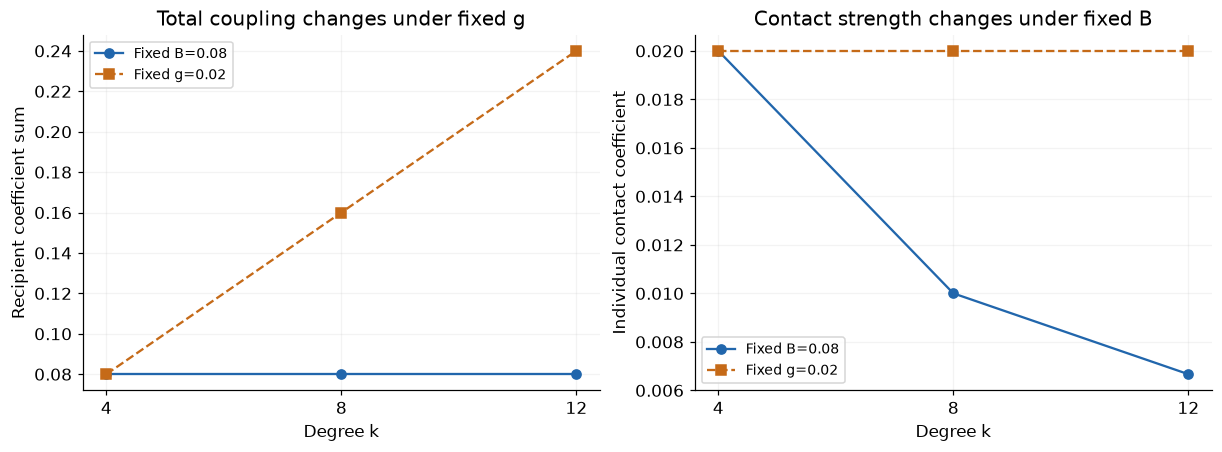

In [4]:
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained');kk=np.array(DEGREES)
for convention,color,style,label in [('fixed_budget',BLUE,'o-','Fixed B=0.08'),('fixed_contact',ORANGE,'s--','Fixed g=0.02')]:
 p=coefficients[(coefficients.panel=='degree')&(coefficients.family=='ring')&(coefficients.convention==convention)].sort_values('degree')
 axs[0].plot(kk,p.budget,style,color=color,label=label);axs[1].plot(kk,p.edge_coefficient,style,color=color,label=label)
axs[0].set(ylabel='Recipient coefficient sum',title='Total coupling changes under fixed g')
axs[1].set(ylabel='Individual contact coefficient',title='Contact strength changes under fixed B')
for ax in axs:ax.set(xticks=kk,xlabel='Degree k');ax.legend(fontsize=9)
save(fig,'01_coupling_conventions')

## 2. Describe the realized graphs
Structural statistics co-vary with degree and size, and are not standalone stability tests for reversal-current synapses. Lines connect chosen specifications, not nested random graph realizations. Missing path lengths would indicate disconnected graphs rather than an arbitrary component convention.

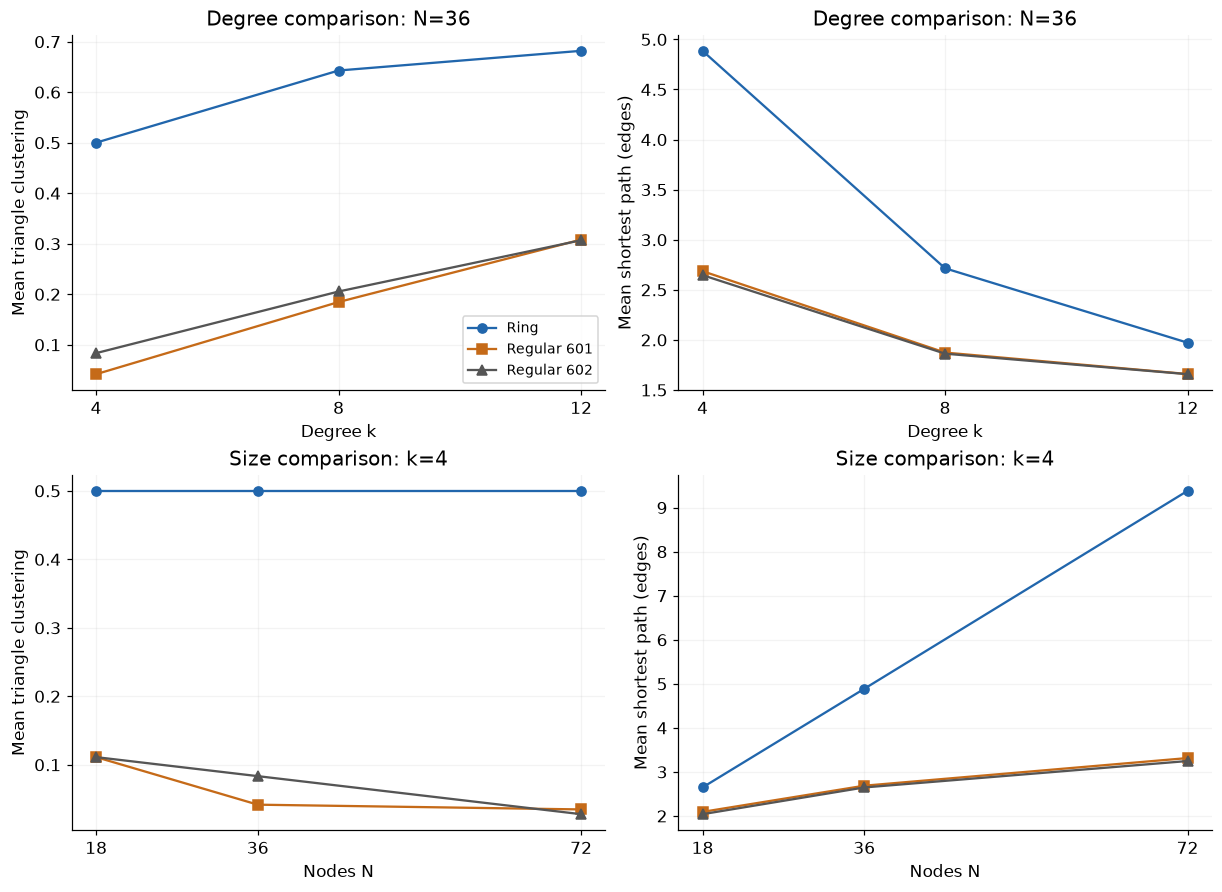

In [6]:
fig,axs=plt.subplots(2,2,figsize=(11,8),layout='constrained')
for row,(selection,xfield,xvals,title) in enumerate([((structure.nodes==36),'degree',DEGREES,'Degree comparison: N=36'),((structure.degree==4),'nodes',SIZES,'Size comparison: k=4')]):
 for col,(metric,ylabel) in enumerate([('clustering','Mean triangle clustering'),('mean_path_length','Mean shortest path (edges)')]):
  ax=axs[row,col]
  for family,marker in zip(FAMILIES,['o','s','^']):
   part=structure[selection&(structure.family==family)].sort_values(xfield)
   ax.plot(part[xfield],part[metric],marker=marker,color=FAMILY_COLOR[family],label=FAMILY_LABEL[family])
  ax.set(xlabel='Degree k' if xfield=='degree' else 'Nodes N',xticks=xvals,ylabel=ylabel,title=title)
axs[0,0].legend(fontsize=9)
save(fig,'02_graph_structure_controls')

## 3. Use a size-independent solver and matched phase initialization
The integrator infers node count from each initial state. Initial v,w lie on a settled isolated limit cycle; all gates start at zero. The initial phase vector is shared across all conditions with the same N and phase seed. Actual kernel versions and all initial states are saved. Integration uses DOP853, rtol 10⁻¹⁰, atol 10⁻¹², max step 0.25, with a sparse analytic Jacobian available for Radau.

In [8]:
def inputs(v,s,G,E):return G@(s*E)-v*(G@s)
def rhs_values(y,currents,G,E):
 v,w,s=y.reshape(-1,3).T
 return np.column_stack((v-v**3/3-w+currents+inputs(v,s,G,E),EPS*(v+A_REC-B_REC*w),
  ALPHA*expit(v/WIDTH)*(1-s)-BETA*s)).ravel()
def jacobian(y,G,E):
 n=len(E);v,w,s=y.reshape(n,3).T;q=expit(v/WIDTH);J=lil_matrix((3*n,3*n))
 degree=G@s
 for i in range(n):
  J[3*i,3*i]=1-v[i]**2-degree[i];J[3*i,3*i+1]=-1
  J[3*i+1,3*i]=EPS;J[3*i+1,3*i+1]=-EPS*B_REC
  J[3*i+2,3*i]=ALPHA*q[i]*(1-q[i])*(1-s[i])/WIDTH
  J[3*i+2,3*i+2]=-ALPHA*q[i]-BETA
  for j in G.getrow(i).indices:J[3*i,3*j+2]=G[i,j]*(E[j]-v[i])
 return J.tocsr()
def integrate(initial,G,E,end=END,method='DOP853',rtol=1e-10,atol=1e-12):
 initial=np.asarray(initial,float);G=np.asarray(G,float);E=np.asarray(E,float);n=len(E)
 if initial.shape!=(n,3) or G.shape!=(n,n):raise ValueError('Shape mismatch')
 if not np.isfinite(initial).all() or not np.isfinite(G).all() or not np.isfinite(E).all() or np.any(G<0) or np.any(np.diag(G)!=0):raise ValueError('Invalid state or conductance')
 if np.any(initial[:,2]<0) or np.any(initial[:,2]>1):raise ValueError('Initial gate outside [0,1]')
 Gs=csr_matrix(G);events=[]
 for i in range(n):
  def event(t,y,index=i):return y[3*index]
  event.direction=1;event.terminal=False;events.append(event)
 options={}
 if method in ['Radau','BDF']:options['jac']=lambda t,y:jacobian(y,Gs,E)
 sol=solve_ivp(lambda t,y:rhs_values(y,.5,Gs,E),(0,end),initial.ravel(),method=method,
  rtol=rtol,atol=atol,events=events,dense_output=True,max_step=.25,**options)
 if not sol.success:raise RuntimeError(sol.message)
 return sol
iso=integrate([[2.,-.5,0.]],np.zeros((1,1)),np.array([3.]),end=800.,rtol=1e-10,atol=1e-12)
t0,t1=iso.t_events[0][-2:];PERIOD=t1-t0

INITIAL={};PHASES={};init_rows=[]
for n in SIZES:
 for seed in PHASE_SEEDS:
  phases=np.random.default_rng(seed).uniform(0,1,n);states=iso.sol(t0+phases*PERIOD).reshape(3,n).T;states[:,2]=0
  INITIAL[(n,seed)]=states;PHASES[(n,seed)]=phases
  for node,(phase,z) in enumerate(zip(phases,states)):init_rows.append(dict(nodes=n,phase_seed=seed,node=node,phase_fraction=phase,v=z[0],w=z[1],s=z[2]))
pd.DataFrame(init_rows).to_csv(OUT/'initial_states.csv',index=False)
print('Reference isolated period:',PERIOD)


Reference isolated period: 39.474414980238635


## 4. Measure once and reuse exact duplicates
There are **78 design labels**: degree 36, size 18, strength 24. Cache a trajectory only when node count, initial phase seed, source assignment and the entire G matrix match exactly. k=4 conventions coincide; specifications shared between panels reuse the same run; at B=0 all three graph supports give the same uncoupled system. Reuse is recorded explicitly and is not statistical replication.

Observe 400–1000. Positive v=0 event counts divided by 600 define node frequency. Interpolate phase only between available events, without extrapolation. Global phase order R averages over times supported by every node; saved coverage may change with N and dynamics. Node E/I input, frequency and ISI variability and global centered v,w spread are recorded.

Local uncancelled fraction is $C=\langle|J_E+J_I|\rangle/\langle|J_E|+|J_I|\rangle$, with absolute values before averaging. **C is undefined (NaN) at zero input**, not zero or one. It is not a physiological balance certificate. With B=0, v,w dynamics reduce exactly to independent isolated FHN neurons; ideal event-phase order equals the magnitude of the initial mean phase phasor, which provides an analytic benchmark.

In [10]:
def phase_order(phase,mask):
 if not np.any(mask):return np.nan,0.
 valid=np.isfinite(phase[mask]).all(axis=0)
 if not valid.any():return np.nan,0.
 return float(np.abs(np.mean(np.exp(1j*phase[mask][:,valid]),axis=0)).mean()),float(valid.mean())
def measure(sol,mask,G,start=BURN,stop=END):
 n=len(mask);times=np.arange(start,stop+DT/10,DT);z=sol.sol(times).reshape(n,3,-1);v,w,s=z[:,0],z[:,1],z[:,2]
 G=csr_matrix(G);E=np.where(mask,3.,-3.)
 JE=inputs(v,s*mask[:,None],G,E[:,None]);JI=inputs(v,s*(~mask)[:,None],G,E[:,None])
 phase=np.full((n,len(times)),np.nan);node_rows=[]
 for i,e in enumerate(sol.t_events):
  recent=e[(e>=start)&(e<=stop)];isi=np.diff(recent)
  if len(e)>=2:
   valid=(times>=e[0])&(times<=e[-1]);phase[i,valid]=np.interp(times[valid],e,2*np.pi*np.arange(len(e)))
  node_rows.append(dict(node=i,source_type='E' if mask[i] else 'I',window_spikes=len(recent),count_frequency=len(recent)/(stop-start),
   period_frequency=float(1/isi.mean()) if len(isi)>=2 else np.nan,isi_cv=float(isi.std()/isi.mean()) if len(isi)>=2 else np.nan,
   mean_E_input=float(JE[i].mean()),mean_I_input=float(JI[i].mean()),rms_E_input=float(np.sqrt(np.mean(JE[i]**2))),rms_I_input=float(np.sqrt(np.mean(JI[i]**2)))))
 nodes=pd.DataFrame(node_rows);centered=z[:,:2]-z[:,:2].mean(axis=0,keepdims=True)
 total=float(np.mean(abs(JE)+abs(JI)));C=float(np.mean(abs(JE+JI))/total) if total>1e-15 else np.nan
 row=dict(state_spread=float(np.sqrt(np.mean(np.sum(centered**2,axis=1)))),mean_count_frequency=float(nodes.count_frequency.mean()),
  std_count_frequency=float(nodes.count_frequency.std(ddof=0)),nodes_with_spikes=int((nodes.window_spikes>0).sum()),
  mean_E_input=float(JE.mean()),mean_I_input=float(JI.mean()),local_uncancelled_fraction=C,
  E_count=int(mask.sum()),I_count=int((~mask).sum()))
 for name,pop in [('all',np.ones(n,dtype=bool)),('E',mask),('I',~mask)]:
  order,coverage=phase_order(phase,pop);row[f'phase_order_{name}']=order;row[f'phase_coverage_{name}']=coverage
  row[f'count_frequency_{name}']=float(nodes.loc[pop,'count_frequency'].mean()) if pop.any() else np.nan
 return row,nodes

cache={};mapped=[];unique_rows=[];node_tables=[];event_rows=[];bounds=[];SELECTED={}
for index,condition in design.iterrows():
 n=int(condition.nodes);seed=int(condition.phase_seed);G=MATRICES[condition.matrix_id];mask=SOURCE[n];E=np.where(mask,3.,-3.)
 key=(n,seed,mask.tobytes(),G.tobytes())
 if key not in cache:
  run_id=f'run_{len(cache)+1:03d}';sol=integrate(INITIAL[(n,seed)],G,E)
  stats,node_stats=measure(sol,mask,G);unique_rows.append(dict(run_id=run_id,nodes=n,phase_seed=seed,**stats))
  node_stats['run_id']=run_id;node_tables.append(node_stats)
  for node,e in enumerate(sol.t_events):event_rows.extend(dict(run_id=run_id,node=node,time=float(t)) for t in e)
  z=sol.sol(np.linspace(0,END,2001)).reshape(n,3,-1)
  bounds.append(dict(run_id=run_id,min_v=float(z[:,0].min()),max_v=float(z[:,0].max()),min_s=float(z[:,2].min()),max_s=float(z[:,2].max())))
  cache[key]=run_id
 else:run_id=cache[key];sol=None
 mapped.append(dict(design_id=f'design_{index+1:03d}',**condition.to_dict(),run_id=run_id))
 keep=(seed==11) and ((n==36 and condition.degree==4 and condition.family=='ring') or (n==72 and condition.family=='regular601' and condition.panel=='size') or (n==36 and condition.degree==12 and condition.family=='ring' and condition.convention=='fixed_contact'))
 if keep:
  label=f'{n}_{int(condition.degree)}_{condition.family}_{condition.budget:.2f}'
  if label not in SELECTED:
   assert sol is not None, 'Selected diagnostics must be retained from the original unique run'
   SELECTED[label]=sol
 _=(OUT/'progress.json').write_text(json.dumps(dict(status='running',conditions_processed=index+1,total_conditions=len(design),unique_runs=len(cache))))
mapping=pd.DataFrame(mapped);mapping.to_csv(OUT/'design_to_run.csv',index=False)
unique=pd.DataFrame(unique_rows);unique.to_csv(OUT/'unique_run_metrics.csv',index=False)
scan=mapping.merge(unique.drop(columns=['nodes','phase_seed']),on='run_id',validate='many_to_one');scan.to_csv(OUT/'condition_metrics.csv',index=False)
pd.concat(node_tables,ignore_index=True).to_csv(OUT/'node_metrics.csv',index=False)
pd.DataFrame(event_rows).to_csv(OUT/'spike_events.csv',index=False)
bound_table=pd.DataFrame(bounds);bound_table.to_csv(OUT/'sampled_bounds.csv',index=False)
display(scan[(scan.phase_seed==11)&(scan.panel=='degree')][['family','degree','convention','budget','mean_count_frequency','phase_order_all','local_uncancelled_fraction']].round(5))
print(len(scan),'design labels;',len(unique),'unique main conditions.')


,family,degree,convention,budget,mean_count_frequency,phase_order_all,local_uncancelled_fraction
0,ring,4,fixed_budget,0.08,0.02611,0.21863,0.45919
2,ring,4,fixed_contact,0.08,0.02611,0.21863,0.45919
4,regular601,4,fixed_budget,0.08,0.02574,0.67394,0.44347
6,regular601,4,fixed_contact,0.08,0.02574,0.67394,0.44347
8,regular602,4,fixed_budget,0.08,0.02611,0.08659,0.45150
10,regular602,4,fixed_contact,0.08,0.02611,0.08659,0.45150
12,ring,8,fixed_budget,0.08,0.02634,0.49150,0.42891
14,ring,8,fixed_contact,0.16,0.02704,0.39981,0.40511
16,regular601,8,fixed_budget,0.08,0.02519,0.61486,0.38001
18,regular601,8,fixed_contact,0.16,0.02653,0.75015,0.37806


78 design labels; 56 unique main conditions.


## 5. Degree sweep: compare the two coupling conventions
Each curve is a graph family/draw and initial phase field; curves are not confidence intervals. The column difference combines different total strength and different contact strength at k>4. E/I labels and initial fields are matched, but E/I contact composition and other graph features can change with degree.

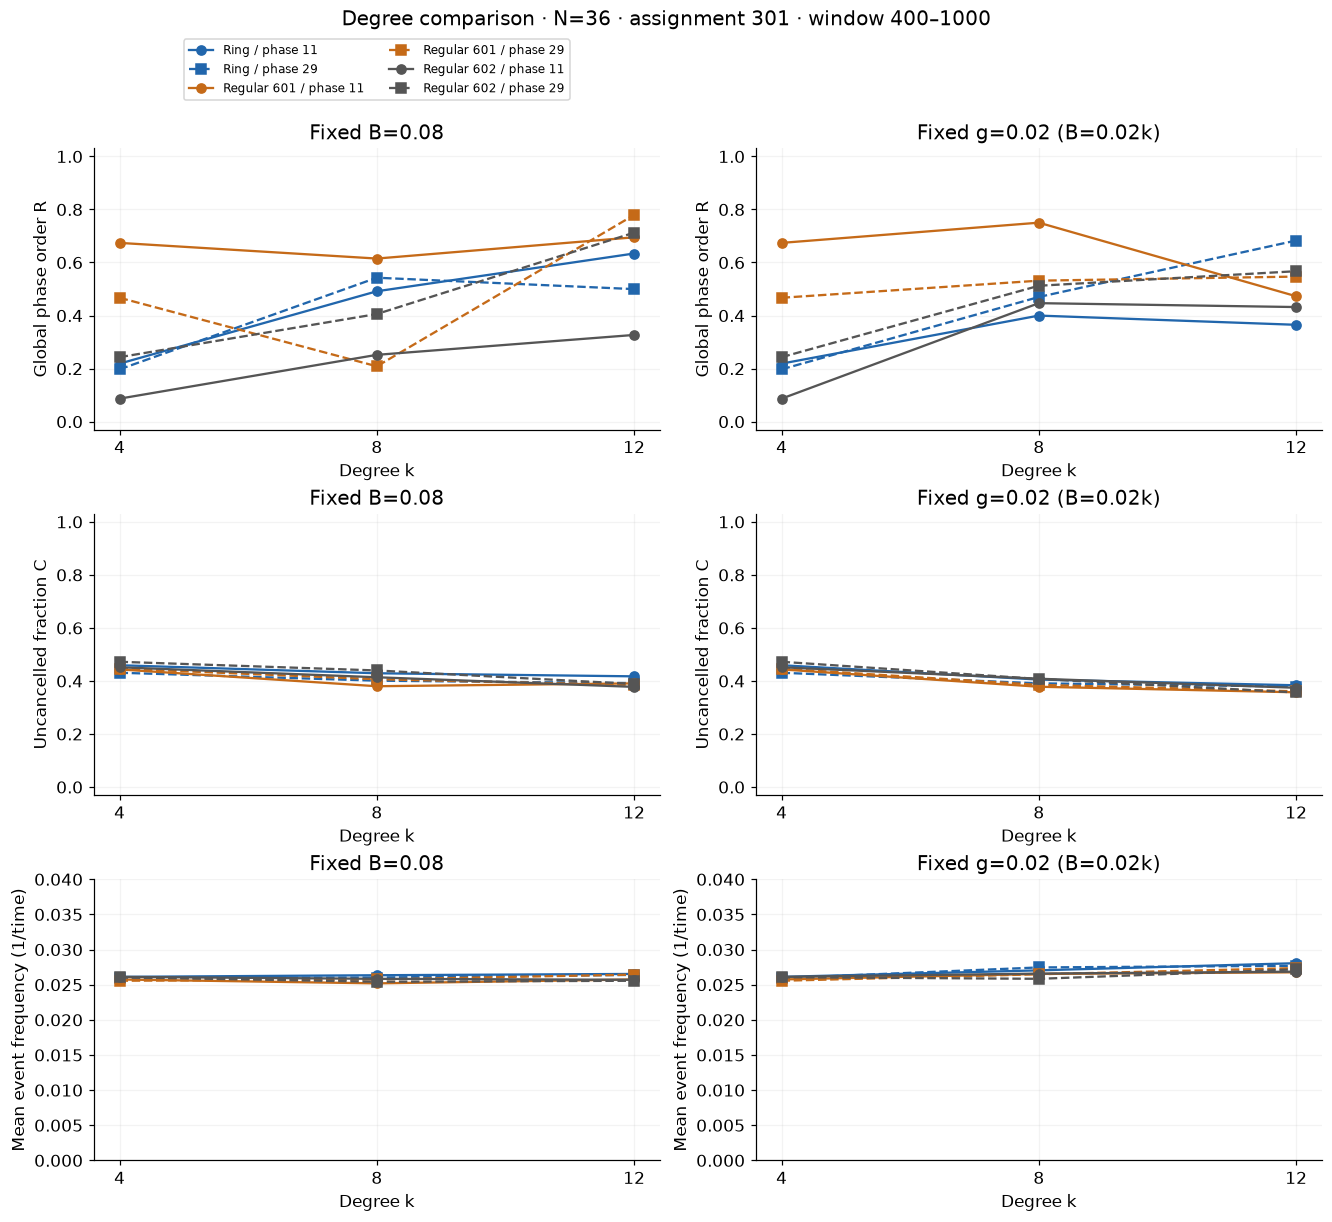

In [12]:
fig,axs=plt.subplots(3,2,figsize=(12,11),layout='constrained')
metrics=[('phase_order_all','Global phase order R'),('local_uncancelled_fraction','Uncancelled fraction C'),('mean_count_frequency','Mean event frequency (1/time)')]
for col,convention in enumerate(['fixed_budget','fixed_contact']):
 for row,(metric,ylabel) in enumerate(metrics):
  ax=axs[row,col]
  for family in FAMILIES:
   for seed,marker,style in [(11,'o','-'),(29,'s','--')]:
    p=scan[(scan.panel=='degree')&(scan.convention==convention)&(scan.family==family)&(scan.phase_seed==seed)].sort_values('degree')
    ax.plot(p.degree,p[metric],marker=marker,linestyle=style,color=FAMILY_COLOR[family],label=f'{FAMILY_LABEL[family]} / phase {seed}')
  ax.set(xticks=DEGREES,xlabel='Degree k',ylabel=ylabel,title='Fixed B=0.08' if convention=='fixed_budget' else 'Fixed g=0.02 (B=0.02k)')
  ax.set_ylim((-0.03,1.03) if row<2 else (0,.04))
axs[0,0].legend(fontsize=8,ncol=2,loc='lower center',bbox_to_anchor=(.5,1.15))
fig.suptitle('Degree comparison · N=36 · assignment 301 · window 400–1000',fontsize=13)
save(fig,'03_degree_and_budget_dynamics')

## 6. Size sweep: preserve degree, coefficient budget and source fraction
All contacts have coefficient 0.02 here. Density changes from 4/(N−1), the random graphs are regenerated, and exact-half source assignments are not nested. R can depend on population size, event-phase coverage and finite-window transients. Three sizes and two graph draws do not establish a finite-size scaling law.

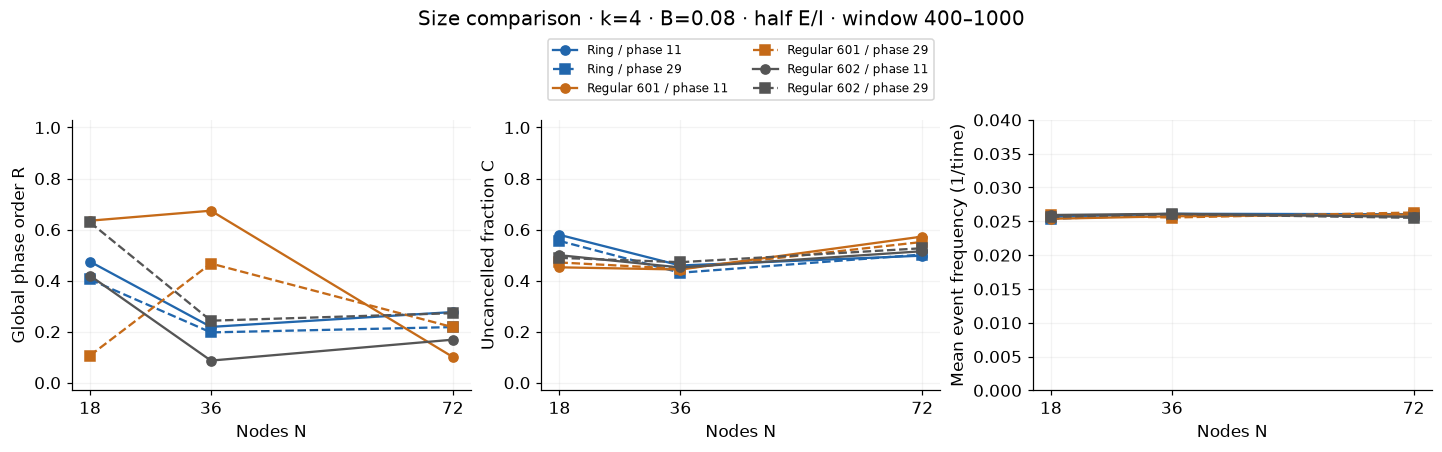

In [14]:
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,(metric,ylabel) in zip(axs,metrics):
 for family in FAMILIES:
  for seed,marker,style in [(11,'o','-'),(29,'s','--')]:
   p=scan[(scan.panel=='size')&(scan.family==family)&(scan.phase_seed==seed)].sort_values('nodes')
   ax.plot(p.nodes,p[metric],marker=marker,linestyle=style,color=FAMILY_COLOR[family],label=f'{FAMILY_LABEL[family]} / phase {seed}')
 ax.set(xticks=SIZES,xlabel='Nodes N',ylabel=ylabel)
 ax.set_ylim((-.03,1.03) if metric!='mean_count_frequency' else (0,.04))
axs[1].legend(fontsize=8,ncol=2,loc='lower center',bbox_to_anchor=(.5,1.05))
fig.suptitle('Size comparison · k=4 · B=0.08 · half E/I · window 400–1000',fontsize=13)
save(fig,'04_finite_size_dynamics')

## 7. Coupling sweep: reuse the same graphs and initial fields
This comparison holds each graph, E/I label and initial state fixed while changing B. B=0 is an uncoupled control shared by all graph supports at each phase seed. Global R need not be zero for a finite deterministic sample of uncoupled initial phases. C is not defined at B=0; its curve begins at the first nonzero budget.

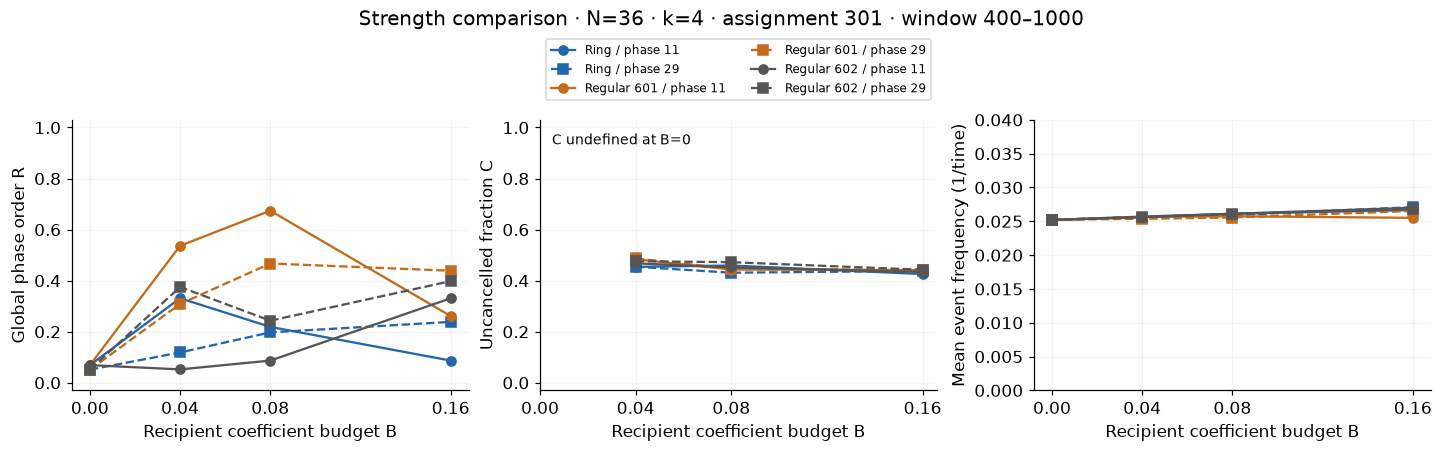

In [16]:
fig,axs=plt.subplots(1,3,figsize=(13,4),layout='constrained')
for ax,(metric,ylabel) in zip(axs,metrics):
 for family in FAMILIES:
  for seed,marker,style in [(11,'o','-'),(29,'s','--')]:
   p=scan[(scan.panel=='strength')&(scan.family==family)&(scan.phase_seed==seed)].sort_values('budget')
   ax.plot(p.budget,p[metric],marker=marker,linestyle=style,color=FAMILY_COLOR[family],label=f'{FAMILY_LABEL[family]} / phase {seed}')
 ax.set(xticks=BUDGETS,xlabel='Recipient coefficient budget B',ylabel=ylabel)
 ax.set_ylim((-.03,1.03) if metric!='mean_count_frequency' else (0,.04))
axs[1].text(.03,.95,'C undefined at B=0',transform=axs[1].transAxes,fontsize=9,va='top')
axs[1].legend(fontsize=8,ncol=2,loc='lower center',bbox_to_anchor=(.5,1.05))
fig.suptitle('Strength comparison · N=36 · k=4 · assignment 301 · window 400–1000',fontsize=13)
save(fig,'05_coupling_strength_dynamics')

## 8. Quantify the convention contrast on matched graphs
Subtract fixed-contact results from fixed-budget results for the same degree, graph and phase field. Every k=4 difference must be exactly zero because both design labels map to the same numerical run. At k>4 this contrast is a coupling-convention effect on a fixed graph, not the effect of degree alone.

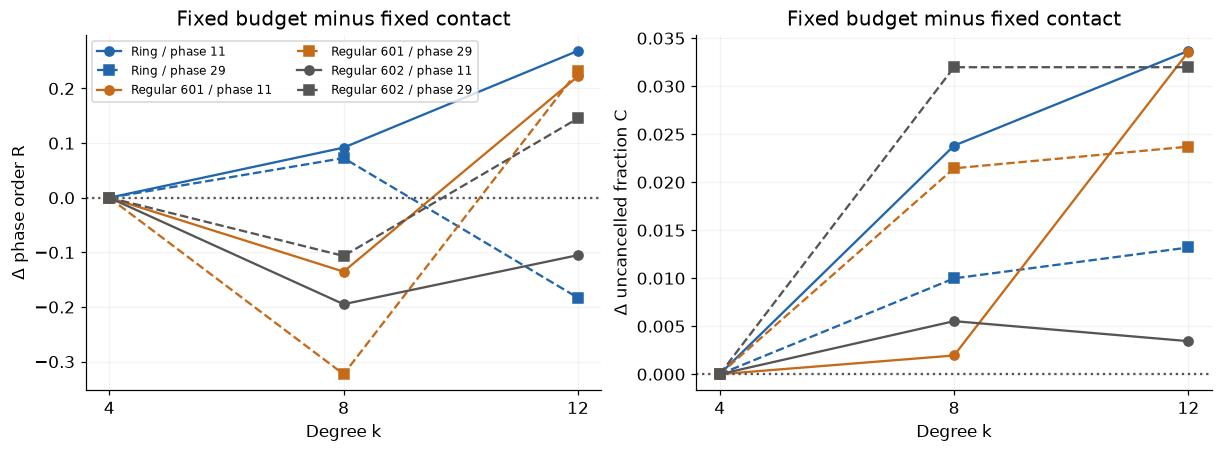

In [18]:
contrasts=[]
for family in FAMILIES:
 for seed in PHASE_SEEDS:
  for k in DEGREES:
   p=scan[(scan.panel=='degree')&(scan.family==family)&(scan.phase_seed==seed)&(scan.degree==k)].set_index('convention')
   contrasts.append(dict(family=family,phase_seed=seed,degree=k,delta_R=p.loc['fixed_budget','phase_order_all']-p.loc['fixed_contact','phase_order_all'],delta_C=p.loc['fixed_budget','local_uncancelled_fraction']-p.loc['fixed_contact','local_uncancelled_fraction']))
contrasts=pd.DataFrame(contrasts);contrasts.to_csv(OUT/'coupling_convention_contrasts.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,metric,ylabel in [(axs[0],'delta_R','Δ phase order R'),(axs[1],'delta_C','Δ uncancelled fraction C')]:
 for family in FAMILIES:
  for seed,marker,style in [(11,'o','-'),(29,'s','--')]:
   p=contrasts[(contrasts.family==family)&(contrasts.phase_seed==seed)].sort_values('degree')
   ax.plot(p.degree,p[metric],marker=marker,linestyle=style,color=FAMILY_COLOR[family],label=f'{FAMILY_LABEL[family]} / phase {seed}')
 ax.axhline(0,color=GRAY,linestyle=':');ax.set(xticks=DEGREES,xlabel='Degree k',ylabel=ylabel,title='Fixed budget minus fixed contact')
axs[0].legend(fontsize=8,ncol=2)
save(fig,'06_matched_convention_contrasts')

## 9. Inspect the ring coupling examples
At N=36, k=4, phase seed 11, compare B=0.04,0.08,0.16 over 800–1000. Rasters group E then I rather than physical location. Population mean v is an activity view, not by itself a synchrony or balance measure. Blue denotes E and orange I in this figure.

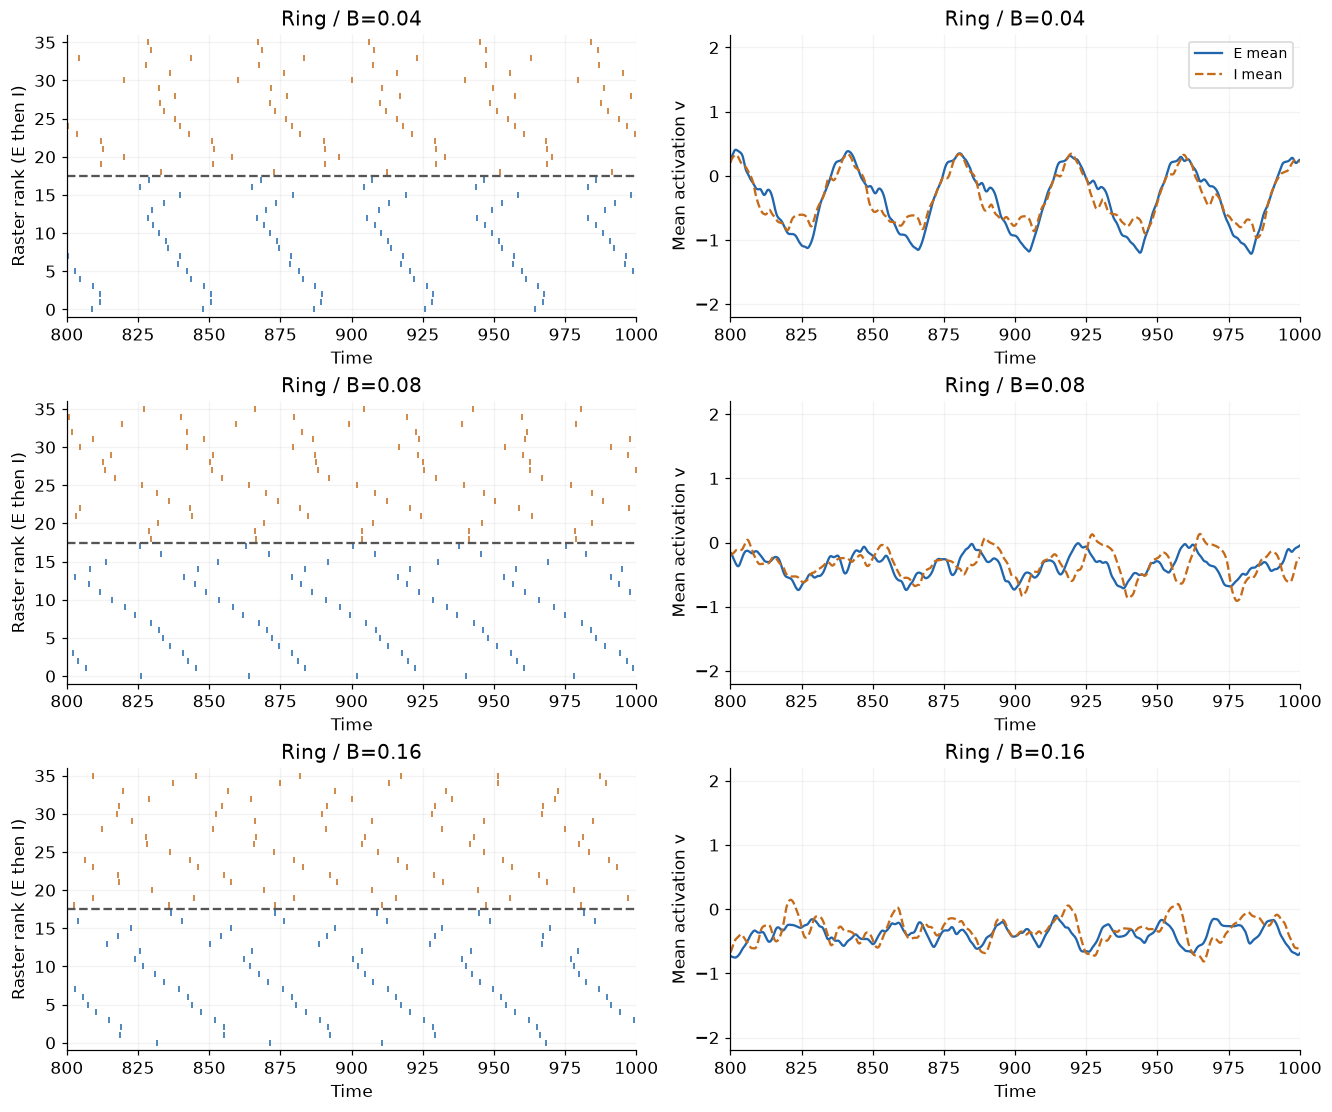

In [20]:
fig,axs=plt.subplots(3,2,figsize=(12,10),layout='constrained');times=np.linspace(800,1000,1001);mask=SOURCE[36]
for row,budget in enumerate([.04,.08,.16]):
 sol=SELECTED[f'36_4_ring_{budget:.2f}'];order=np.r_[np.flatnonzero(mask),np.flatnonzero(~mask)]
 for rank,node in enumerate(order):
  e=sol.t_events[node];e=e[(e>=800)&(e<=1000)];axs[row,0].plot(e,np.full(len(e),rank),'|',color=BLUE if mask[node] else ORANGE,markersize=4)
 axs[row,0].axhline(17.5,color=GRAY,linestyle='--');axs[row,0].set(xlim=(800,1000),ylim=(-1,36),xlabel='Time',ylabel='Raster rank (E then I)',title=f'Ring / B={budget:.2f}')
 v=sol.sol(times).reshape(36,3,-1)[:,0]
 for pop,color,style,label in [(mask,BLUE,'-','E mean'),(~mask,ORANGE,'--','I mean')]:axs[row,1].plot(times,v[pop].mean(axis=0),color=color,linestyle=style,label=label)
 axs[row,1].set(xlim=(800,1000),ylim=(-2.2,2.2),xlabel='Time',ylabel='Mean activation v',title=f'Ring / B={budget:.2f}')
axs[0,1].legend(fontsize=9)
save(fig,'07_ring_coupling_rasters')

## 10. Validate rescaling, caching and selected numerical accuracy
Check regular degree, simple undirected support, E/I counts, actual coefficient budgets, exact duplicate reuse, and zero-input analytic phase order/undefined C. The node-count inference is checked by all three sizes and the uncoupled benchmark.

Audit two selected extremes: a 72-node degree-4 random graph at B=0.08 and a 36-node degree-12 ring at fixed g=0.02 (B=0.24). Each receives independent Radau comparison on 0–200 and tighter DOP853 on 0–1000. Extend selected ring B=0.04,0.08,0.16 runs to 2000, keeping the early window's event support identical to the main run. These are selected accuracy and transient checks, not certification of all trajectories.

,check,error,limit,passed
128,"Sampled gates [0,1]",0.000000e+00,1.000000e-08,True
129,Sampled activation inside reversals,0.000000e+00,1.000000e-08,True
130,Mean E current nonnegative,0.000000e+00,1.000000e-10,True
131,Mean I current nonpositive,0.000000e+00,1.000000e-10,True
132,"Phase orders in [0,1]",0.000000e+00,1.000000e-12,True
133,72_4_regular601_0.08: independent state 0–200,2.947379e-09,2.000000e-04,True
134,72_4_regular601_0.08: independent event 0–200,1.866283e-09,2.000000e-04,True
135,72_4_regular601_0.08: tighter state 0–1000,2.913447e-07,2.000000e-03,True
136,72_4_regular601_0.08: tighter event 0–1000,2.053566e-07,2.000000e-03,True
137,36_12_ring_0.24: independent state 0–200,4.547439e-09,2.000000e-04,True


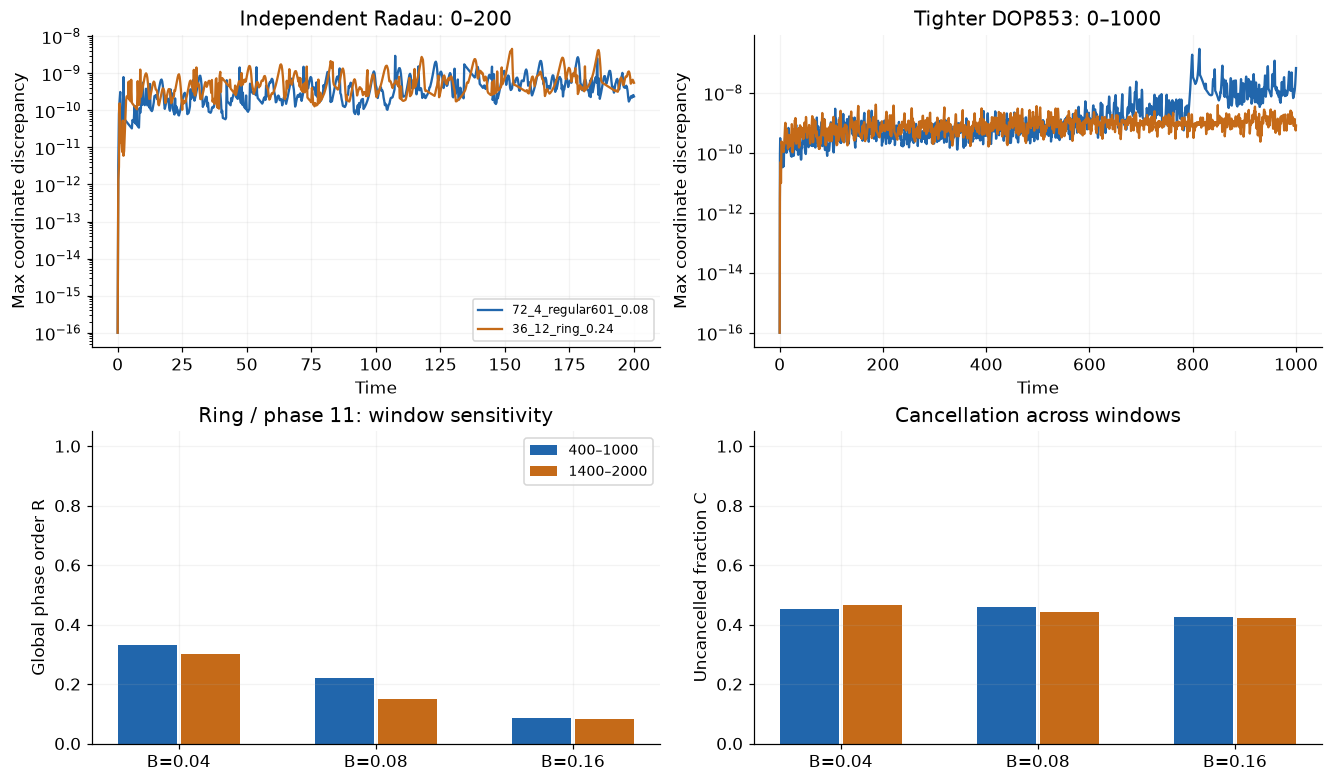

78 labels; 56 unique main conditions; 144 checks passed.


In [11]:
checks=[]
def check(name,error,limit):checks.append(dict(check=name,error=float(error),limit=float(limit),passed=bool(error<limit)))
for name,A in ADJ.items():
 n,k=GRAPH_INFO[name]['nodes'],GRAPH_INFO[name]['degree']
 check(name+': degree',abs(A.sum(axis=1)-k).max(),1e-12)
 check(name+': simple symmetric',abs(A-A.T).max()+abs(np.diag(A)).max()+np.minimum(abs(A),abs(A-1)).max(),1e-12)
for i,r in coefficients.iterrows():
 G=MATRICES[r.matrix_id]
 check(f'Coefficients {i}: row/column sums',abs(G.sum(axis=1)-r.budget).max()+abs(G.sum(axis=0)-r.budget).max(),1e-12)
 check(f'Coefficients {i}: support/weight',abs(G-r.edge_coefficient*ADJ[r.graph]).max(),1e-12)
for n,mask in SOURCE.items():check(f'N={n}: exact half E/I',abs(mask.sum()-n//2),.5)
check('78 design labels',abs(len(scan)-78),.5)
check('56 unique main conditions',abs(len(unique)-56),.5)
check('Zero k=4 convention contrasts',abs(contrasts[contrasts.degree==4][['delta_R','delta_C']].to_numpy()).max(),1e-12)
for family in FAMILIES:
 for seed in PHASE_SEEDS:
  p=scan[(scan.panel=='degree')&(scan.family==family)&(scan.degree==4)&(scan.phase_seed==seed)]
  check(f'{family}/{seed}: conventions reuse one run',abs(p.run_id.nunique()-1),.5)
for seed in PHASE_SEEDS:
 p=scan[(scan.panel=='strength')&(scan.budget==0)&(scan.phase_seed==seed)]
 check(f'Zero coupling phase {seed}: one shared run',abs(p.run_id.nunique()-1),.5)
 stats=p.iloc[0];expected=abs(np.exp(2j*np.pi*PHASES[(36,seed)]).mean())
 check(f'Zero coupling phase {seed}: analytic phase order',abs(stats.phase_order_all-expected),2e-5)
 check(f'Zero coupling phase {seed}: no input',abs(stats.mean_E_input)+abs(stats.mean_I_input),1e-14)
 check(f'Zero coupling phase {seed}: C undefined',0 if np.isnan(stats.local_uncancelled_fraction) else 1,.5)
check('Sampled gates [0,1]',max(0.,-bound_table.min_s.min(),bound_table.max_s.max()-1),1e-8)
check('Sampled activation inside reversals',max(0.,-3-bound_table.min_v.min(),bound_table.max_v.max()-3),1e-8)
check('Mean E current nonnegative',max(0.,-unique.mean_E_input.min()),1e-10)
check('Mean I current nonpositive',max(0.,unique.mean_I_input.max()),1e-10)
check('Phase orders in [0,1]',max(0.,-unique.phase_order_all.min(),unique.phase_order_all.max()-1),1e-12)
audit_rows=[];ERROR_CURVES={}
AUDITS=[(72,4,'regular601',.08),(36,12,'ring',.24)]
for n,k,family,budget in AUDITS:
 label=f'{n}_{k}_{family}_{budget:.2f}';selected=SELECTED[label];G=(budget/k)*ADJ[graph_name(n,k,family)];mask=SOURCE[n];E=np.where(mask,3.,-3.)
 short_times=np.linspace(0,200,801);reference=integrate(INITIAL[(n,11)],G,E,end=200.,method='Radau',rtol=2e-11,atol=2e-13)
 short_curve=abs(selected.sol(short_times)-reference.sol(short_times)).max(axis=0);independent_error=float(short_curve.max());check(label+': independent state 0–200',independent_error,2e-4)
 independent_event_error=0.
 for e,er in zip(selected.t_events,reference.t_events):
  e=e[e<=200];assert len(e)==len(er)
  if len(e):independent_event_error=max(independent_event_error,float(abs(e-er).max()))
 check(label+': independent event 0–200',independent_event_error,2e-4)
 full_times=np.linspace(0,END,2001);tight=integrate(INITIAL[(n,11)],G,E,rtol=1e-12,atol=1e-14)
 full_curve=abs(selected.sol(full_times)-tight.sol(full_times)).max(axis=0);tight_error=float(full_curve.max());check(label+': tighter state 0–1000',tight_error,2e-3)
 tight_event_error=0.
 for e,er in zip(selected.t_events,tight.t_events):
  assert len(e)==len(er)
  if len(e):tight_event_error=max(tight_event_error,float(abs(e-er).max()))
 check(label+': tighter event 0–1000',tight_event_error,2e-3)
 audit_rows.append(dict(case=label,independent_horizon=200.,independent_state_error=independent_error,independent_event_error=independent_event_error,tighter_horizon=END,tighter_state_error=tight_error,tighter_event_error=tight_event_error))
 ERROR_CURVES[label]=(short_times,short_curve,full_times,full_curve)
audits=pd.DataFrame(audit_rows);audits.to_csv(OUT/'numerical_audits.csv',index=False)
window_rows=[]
for budget in [.04,.08,.16]:
 label=f'36_4_ring_{budget:.2f}';G=(budget/4)*ADJ[graph_name(36,4,'ring')];mask=SOURCE[36];E=np.where(mask,3.,-3.)
 long=integrate(INITIAL[(36,11)],G,E,end=2000.)
 for start,stop in [(400.,1000.),(1400.,2000.)]:
  stats,_=measure(SELECTED[label] if stop==END else long,mask,G,start,stop)
  window_rows.append(dict(budget=budget,window=f'{int(start)}–{int(stop)}',**stats))
windows=pd.DataFrame(window_rows);windows.to_csv(OUT/'window_sensitivity.csv',index=False)
for budget in [.04,.08,.16]:
 early=windows[(windows.budget==budget)&(windows.window=='400–1000')].iloc[0]
 main=scan[(scan.panel=='strength')&(scan.family=='ring')&(scan.phase_seed==11)&(scan.budget==budget)].iloc[0]
 check(f'B={budget}: early event support unchanged',abs(early.phase_order_all-main.phase_order_all)+abs(early.phase_coverage_all-main.phase_coverage_all),1e-12)
validation=pd.DataFrame(checks);validation.to_csv(OUT/'validation_checks.csv',index=False);display(validation.tail(16));assert validation.passed.all()
fig,axs=plt.subplots(2,2,figsize=(12,7),layout='constrained')
for label,color in zip(ERROR_CURVES,[BLUE,ORANGE]):
 ts,es,tf,ef=ERROR_CURVES[label];axs[0,0].semilogy(ts,np.maximum(es,1e-16),color=color,label=label);axs[0,1].semilogy(tf,np.maximum(ef,1e-16),color=color,label=label)
axs[0,0].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='Independent Radau: 0–200');axs[0,0].legend(fontsize=8)
axs[0,1].set(xlabel='Time',ylabel='Max coordinate discrepancy',title='Tighter DOP853: 0–1000')
xx=np.arange(3)
for window,color,offset in [('400–1000',BLUE,-.16),('1400–2000',ORANGE,.16)]:
 p=windows[windows.window==window].set_index('budget').loc[[.04,.08,.16]]
 axs[1,0].bar(xx+offset,p.phase_order_all,width=.3,color=color,label=window);axs[1,1].bar(xx+offset,p.local_uncancelled_fraction,width=.3,color=color)
for ax in axs[1,:]:ax.set(xticks=xx,xticklabels=['B=0.04','B=0.08','B=0.16'],ylim=(0,1.05))
axs[1,0].set(ylabel='Global phase order R',title='Ring / phase 11: window sensitivity');axs[1,0].legend(fontsize=9)
axs[1,1].set(ylabel='Uncancelled fraction C',title='Cancellation across windows')
save(fig,'08_accuracy_and_window_checks')
summary=dict(versions=versions,sizes=SIZES,degrees=DEGREES,strength_budgets=BUDGETS,graph_families=FAMILIES,graph_seeds=[601,602],source_seed=301,phase_seeds=PHASE_SEEDS,
 graphs=len(GRAPHS),conductance_matrices=len(MATRICES),design_conditions=len(scan),unique_main_runs=len(unique),checks_passed=int(validation.passed.sum()),figures=8,
 duration=END,burn=BURN,sampling_step=DT,solver=dict(method='DOP853',rtol=1e-10,atol=1e-12,max_step=.25),
 parameters=dict(a=A_REC,b=B_REC,epsilon=EPS,current=.5,alpha=ALPHA,beta=BETA,width=WIDTH,E_E=3.,E_I=-3.),numerical_audits=audit_rows)
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
_=(OUT/'progress.json').write_text(json.dumps(dict(status='complete',conditions_processed=len(scan),total_conditions=len(scan),unique_runs=len(unique))))
print(len(scan),'labels;',len(unique),'unique main conditions;',len(checks),'checks passed.')

## Scope and closing interpretation
This completes the requested degree/size/strength stage for the homogeneous FHN E/I model. It is an exploratory collection of finite-window slices, not a full factorial study, bifurcation diagram, universal graph ranking, ensemble estimate or proof of stable synchronization. Two random draws, one exact-half source assignment per size and two phase fields cannot establish confidence intervals. Reused conditions and shared initial fields are correlated.

Degree changes contact composition and other graph properties. Size changes density, populations and graph realization despite fixed degree and budget. The strength sweep changes a coefficient budget, not imposed current. A vanishing-input C is undefined, and finite uncoupled phase order is not a coupling effect. Global phase coverage should be inspected before interpreting differences across N; no unsupported phases are replaced by zero. Selected long windows and numerical audits do not establish convergence or validate every trajectory.

More extensive research could separately broaden graph/source/phase sampling and sizes, map parameter-dependent regimes with continuation and local stability tools, or introduce mixed neuron models with explicit compatible input/output maps. These are separate projects rather than claims delivered by this notebook. Package versions, frozen adjacency/conductance matrices, phase initialization, cache mappings, event data, metrics and audits define the present result. Seeded graph generation can vary across versions; use the frozen matrices when reproducing exact graph realizations.

References: [NetworkX regular graphs](https://networkx.org/documentation/stable/reference/generated/networkx.generators.random_graphs.random_regular_graph.html); [SciPy solve_ivp integration/events](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html); [Neuronal Dynamics reversal currents/gates](https://neuronaldynamics.epfl.ch/online/Ch3.S1.html). These support tool and synaptic conventions, not the chosen finite graph designs or biological calibration. Discrepancy plots have a display floor of 10⁻¹⁶.